# Question Identification

In this assignment, I have to identify whether a sentence from a video lecture is a question or a normal sentence.

I will first clean the data, then convert the text into numbers using different vectorization methods. After that, I will train a few ML models and compare them using ROC curves.

## 1. Importing libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report,
    ConfusionMatrixDisplay
)

## 2. Reading the dataset

In [2]:
df = pd.read_csv("Data Set _Question Identification - Data Set.csv.csv")

print("Rows and columns:", df.shape)
display(df.head())
print(df["label"].value_counts())

Rows and columns: (235110, 3)


,Unnamed: 0,sentence,label
0,0,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,sentence
1,1,"Born and raised in Houston, Texas, she perform...",sentence
2,2,"Managed by her father, Mathew Knowles, the gro...",sentence
3,3,Their hiatus saw the release of Beyoncé's debu...,sentence
4,4,Following the disbandment of Destiny's Child i...,sentence


label
question    131402
sentence    103708
Name: count, dtype: int64


## 3. Cleaning the data

In [3]:
# Removing the extra index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Removing empty rows and duplicate records
df = df.dropna(subset=["sentence", "label"])
df = df.drop_duplicates(subset=["sentence", "label"])

df["sentence"] = df["sentence"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()

# Keeping only the two labels used in this assignment
df = df[df["label"].isin(["question", "sentence"])]
df = df[df["sentence"] != ""]

print("Dataset after cleaning:", df.shape)
print(df["label"].value_counts())

Dataset after cleaning: (231110, 2)
label
question    131237
sentence     99873
Name: count, dtype: int64


## 4. Checking the data

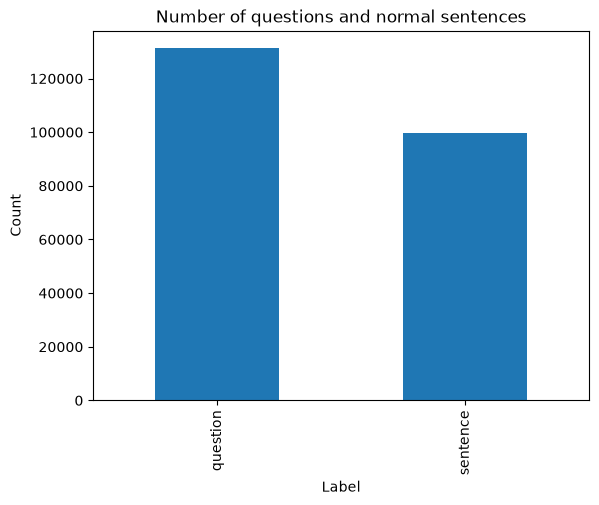

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
question,131237.0,9.859041,3.442233,1.0,7.0,9.0,12.0,40.0
sentence,99873.0,22.489512,12.509054,1.0,14.0,21.0,29.0,323.0


In [4]:
df["length"] = df["sentence"].apply(lambda x: len(x.split()))

df["label"].value_counts().plot(kind="bar")
plt.title("Number of questions and normal sentences")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

display(df.groupby("label")["length"].describe())

## 5. Text preprocessing

I am converting text to lowercase and removing links and extra symbols. I am keeping the question mark because it can help the model identify questions.

I am not removing stop words because words like *what*, *why*, *how* and *is* are useful for this task.

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s?!.,']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_sentence"] = df["sentence"].apply(clean_text)

display(df[["sentence", "clean_sentence", "label"]].head())

,sentence,clean_sentence,label
0,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,beyonc giselle knowles carter bi j nse bee yon...,sentence
1,"Born and raised in Houston, Texas, she perform...","born and raised in houston, texas, she perform...",sentence
2,"Managed by her father, Mathew Knowles, the gro...","managed by her father, mathew knowles, the gro...",sentence
3,Their hiatus saw the release of Beyoncé's debu...,their hiatus saw the release of beyonc 's debu...,sentence
4,Following the disbandment of Destiny's Child i...,following the disbandment of destiny's child i...,sentence


## 6. Splitting the data

In [6]:
# Question = 1 and normal sentence = 0
X = df["clean_sentence"]
y = df["label"].map({"sentence": 0, "question": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape[0])
print("Testing data:", X_test.shape[0])

Training data: 184888
Testing data: 46222


## 7. Vectorization

First, I am trying three text vectorization methods:

1. **Bag of Words:** Counts the words and word pairs.
2. **TF-IDF:** Gives more importance to words that are useful for identifying a sentence.
3. **Character TF-IDF:** Uses character patterns. This can also learn patterns around punctuation and word endings.

In [7]:
vectorizers = {
    "Bag of Words": CountVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2),
    "TF-IDF": TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2),
    "Character TF-IDF": TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5), max_features=20000, min_df=2
    )
}

features = {}

for name, vectorizer in vectorizers.items():
    print("Working on", name)
    train_vec = vectorizer.fit_transform(X_train)
    test_vec = vectorizer.transform(X_test)
    features[name] = (train_vec, test_vec)
    print(train_vec.shape)

Working on Bag of Words
(184888, 20000)
Working on TF-IDF
(184888, 20000)
Working on Character TF-IDF
(184888, 20000)


## 8. Training the models

I am using Naive Bayes, Logistic Regression and Linear SVM. I will compare their results instead of deciding the best model in advance.

Naive Bayes is used with Bag of Words and TF-IDF because it works with non-negative word counts and TF-IDF values.

In [8]:
results = []
roc_values = {}
models = {}

for vector_name, (x_train_vec, x_test_vec) in features.items():

    model_list = [
        ("Logistic Regression", LogisticRegression(max_iter=300, solver="liblinear")),
        ("Linear SVM", LinearSVC())
    ]

    if vector_name != "Character TF-IDF":
        model_list.append(("Naive Bayes", MultinomialNB()))

    for model_name, model in model_list:
        print("Training:", vector_name, "-", model_name)
        model.fit(x_train_vec, y_train)

        prediction = model.predict(x_test_vec)

        if hasattr(model, "predict_proba"):
            score = model.predict_proba(x_test_vec)[:, 1]
        else:
            score = model.decision_function(x_test_vec)

        auc = roc_auc_score(y_test, score)

        results.append({
            "Vectorizer": vector_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, prediction),
            "Precision": precision_score(y_test, prediction, zero_division=0),
            "Recall": recall_score(y_test, prediction, zero_division=0),
            "F1 Score": f1_score(y_test, prediction, zero_division=0),
            "ROC-AUC": auc
        })

        name = vector_name + " + " + model_name
        roc_values[name] = roc_curve(y_test, score)
        models[name] = model

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

Training: Bag of Words - Logistic Regression
Training: Bag of Words - Linear SVM
Training: Bag of Words - Naive Bayes
Training: TF-IDF - Logistic Regression
Training: TF-IDF - Linear SVM
Training: TF-IDF - Naive Bayes
Training: Character TF-IDF - Logistic Regression
Training: Character TF-IDF - Linear SVM


,Vectorizer,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
7,Character TF-IDF,Linear SVM,0.9912,0.9952,0.9892,0.9922,0.9986
6,Character TF-IDF,Logistic Regression,0.9843,0.9892,0.9832,0.9861,0.9977
0,Bag of Words,Logistic Regression,0.9821,0.9862,0.9822,0.9842,0.9967
4,TF-IDF,Linear SVM,0.9825,0.9877,0.9815,0.9846,0.9964
3,TF-IDF,Logistic Regression,0.9811,0.9871,0.9795,0.9833,0.9962
1,Bag of Words,Linear SVM,0.9757,0.9800,0.9772,0.9786,0.9949
2,Bag of Words,Naive Bayes,0.9458,0.9592,0.9448,0.9519,0.9887
5,TF-IDF,Naive Bayes,0.9240,0.9275,0.9397,0.9335,0.9798


## 9. Comparing models with ROC curves

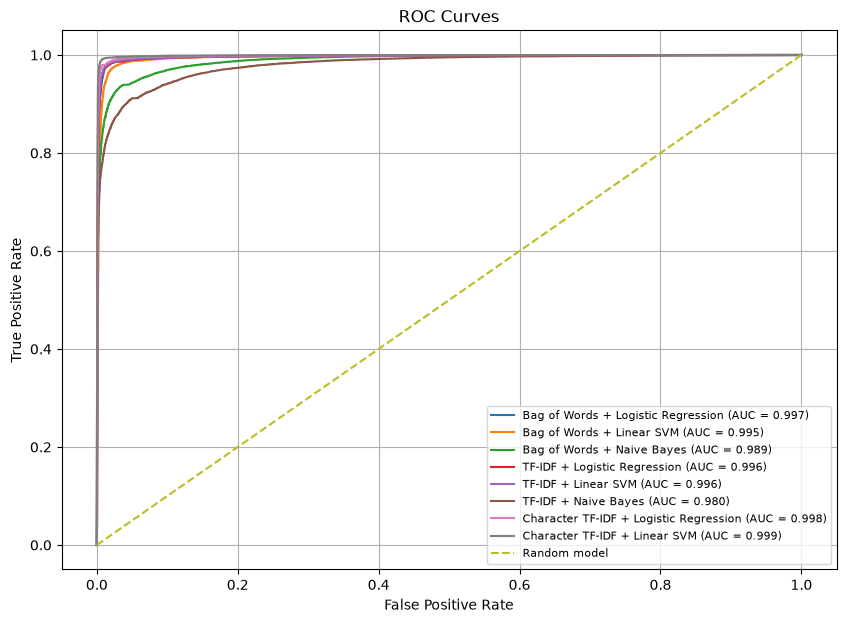

In [9]:
plt.figure(figsize=(10, 7))

for name, values in roc_values.items():
    fpr, tpr, thresholds = values
    auc = results_df.loc[
        (results_df["Vectorizer"] + " + " + results_df["Model"]) == name,
        "ROC-AUC"
    ].iloc[0]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(fontsize=8)
plt.grid()
plt.show()

## 10. Semantic vectorization using Word2Vec

Bag of Words and TF-IDF mainly use word or character patterns. Word2Vec learns word vectors from the context in which words appear.

I will take the average of the word vectors to get one vector for each sentence. Then I will train Logistic Regression on these sentence vectors.

If gensim is not installed, run `%pip install gensim` in a notebook cell.

In [10]:
from gensim.models import Word2Vec

def get_words(text):
    return re.findall(r"[a-z0-9]+", text.lower())

train_words = [get_words(text) for text in X_train]
test_words = [get_words(text) for text in X_test]

word_model = Word2Vec(
    sentences=train_words,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=5,
    seed=42
)

def make_sentence_vector(words):
    word_vectors = [word_model.wv[word] for word in words if word in word_model.wv]

    if len(word_vectors) == 0:
        return np.zeros(100)

    return np.mean(word_vectors, axis=0)

X_train_w2v = np.array([make_sentence_vector(words) for words in train_words])
X_test_w2v = np.array([make_sentence_vector(words) for words in test_words])

print("Training vectors:", X_train_w2v.shape)
print("Testing vectors:", X_test_w2v.shape)

Exception ignored in: Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training vectors: (184888, 100)
Testing vectors: (46222, 100)


## 11. Training a model with Word2Vec

In [11]:
w2v_model = LogisticRegression(max_iter=500)
w2v_model.fit(X_train_w2v, y_train)

w2v_prediction = w2v_model.predict(X_test_w2v)
w2v_score = w2v_model.predict_proba(X_test_w2v)[:, 1]

w2v_auc = roc_auc_score(y_test, w2v_score)

w2v_result = {
    "Vectorizer": "Word2Vec",
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, w2v_prediction),
    "Precision": precision_score(y_test, w2v_prediction, zero_division=0),
    "Recall": recall_score(y_test, w2v_prediction, zero_division=0),
    "F1 Score": f1_score(y_test, w2v_prediction, zero_division=0),
    "ROC-AUC": w2v_auc
}

results_df = pd.concat([results_df, pd.DataFrame([w2v_result])], ignore_index=True)
results_df = results_df.sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

,Vectorizer,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Character TF-IDF,Linear SVM,0.9912,0.9952,0.9892,0.9922,0.9986
1,Character TF-IDF,Logistic Regression,0.9843,0.9892,0.9832,0.9861,0.9977
2,Bag of Words,Logistic Regression,0.9821,0.9862,0.9822,0.9842,0.9967
3,TF-IDF,Linear SVM,0.9825,0.9877,0.9815,0.9846,0.9964
4,TF-IDF,Logistic Regression,0.9811,0.9871,0.9795,0.9833,0.9962
5,Bag of Words,Linear SVM,0.9757,0.9800,0.9772,0.9786,0.9949
6,Bag of Words,Naive Bayes,0.9458,0.9592,0.9448,0.9519,0.9887
8,Word2Vec,Logistic Regression,0.9621,0.9731,0.9597,0.9664,0.9877
7,TF-IDF,Naive Bayes,0.9240,0.9275,0.9397,0.9335,0.9798


## 12. ROC curve for Word2Vec

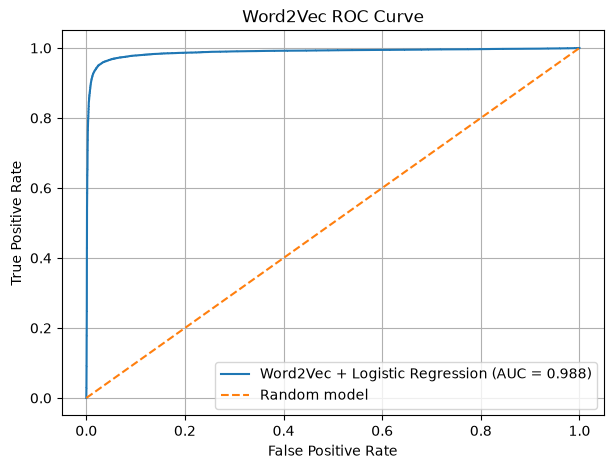

In [12]:
fpr, tpr, thresholds = roc_curve(y_test, w2v_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Word2Vec + Logistic Regression (AUC = {w2v_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Word2Vec ROC Curve")
plt.legend()
plt.grid()
plt.show()

## 13. Selecting the best model

I am selecting the model with the highest ROC-AUC score. ROC-AUC is useful here because it shows how well the model separates questions from normal sentences at different thresholds.

In [13]:
best_result = results_df.iloc[0]
best_name = best_result["Vectorizer"] + " + " + best_result["Model"]

print("Best model:", best_name)
print("ROC-AUC:", round(best_result["ROC-AUC"], 4))
print("Accuracy:", round(best_result["Accuracy"], 4))
print("F1 Score:", round(best_result["F1 Score"], 4))

if best_result["Vectorizer"] == "Word2Vec":
    final_model = w2v_model
    final_prediction = w2v_prediction
else:
    final_model = models[best_name]
    best_test_data = features[best_result["Vectorizer"]][1]
    final_prediction = final_model.predict(best_test_data)

Best model: Character TF-IDF + Linear SVM
ROC-AUC: 0.9986
Accuracy: 0.9912
F1 Score: 0.9922


## 14. Final evaluation

              precision    recall  f1-score   support

    sentence       0.99      0.99      0.99     19975
    question       1.00      0.99      0.99     26247

    accuracy                           0.99     46222
   macro avg       0.99      0.99      0.99     46222
weighted avg       0.99      0.99      0.99     46222



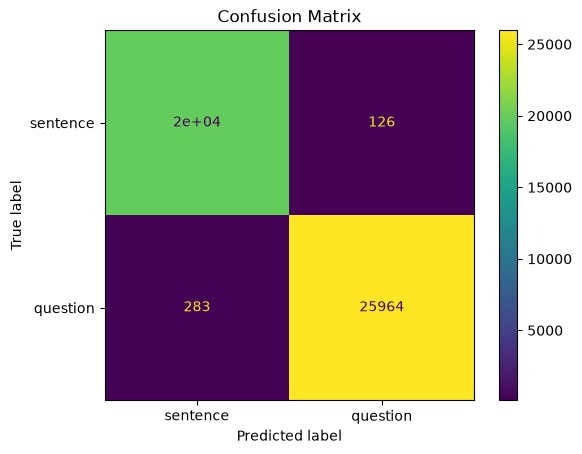

In [14]:
print(classification_report(
    y_test,
    final_prediction,
    target_names=["sentence", "question"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_prediction,
    display_labels=["sentence", "question"]
)
plt.title("Confusion Matrix")
plt.show()

## 15. Checking with new examples

In [15]:
def predict_question(text):
    text = clean_text(text)

    if best_result["Vectorizer"] == "Word2Vec":
        words = get_words(text)
        vector = make_sentence_vector(words).reshape(1, -1)
        prediction = final_model.predict(vector)[0]
    else:
        vectorizer = vectorizers[best_result["Vectorizer"]]
        vector = vectorizer.transform([text])
        prediction = final_model.predict(vector)[0]

    if prediction == 1:
        return "Question"
    return "Normal sentence"

print(predict_question("What is machine learning?"))
print(predict_question("Machine learning is a part of artificial intelligence."))

Question
Normal sentence


## 16. Conclusion

In this assignment, I built a model to identify questions from normal sentences in lecture transcripts.

I cleaned the dataset and prepared the text for machine learning. I tried Bag of Words, TF-IDF and Character TF-IDF as syntactic methods. I also used Word2Vec for semantic vectorization.

I trained Naive Bayes, Logistic Regression and Linear SVM models and compared them using accuracy, precision, recall, F1-score and ROC-AUC. I used ROC curves and a confusion matrix to check the model performance.

The model with the highest ROC-AUC is selected as the final model. The exact scores and the best model are shown in the result table after running the notebook.